# Where events start and what they cost, as one model

Can 01's location model and a model of what each event did share one likelihood, so that where an event started and how much it cost inform each other, and so that the return-period curves for India and for each place in it come from one posterior?

Every event, recorded or not, has a center, a class and a hazard size. Its deaths, people affected and damage read that hazard against the people and the income near its center. EM-DAT records an event only once it kills 10 people or affects 100, or an emergency is declared, so the record is truncated on two of those counts, and that truncation replaces 01's detection curve. Damage is missing for 313 of India's 452 recorded events, and the events missing it are smaller: a median of 13,700 people affected against 500,000 for events that report it. Whether a recorded event reports damage is therefore modeled as a function of its size. The location half keeps 01's rate of event centers without its district offsets, with 02's four hazard covariates and the distance covariates floored at half a cell.

In [1]:
import os

# A JAX Metal plugin is installed, so JAX is pinned to the CPU before anything imports it.
os.environ["JAX_PLATFORMS"] = "cpu"

import warnings

from pathlib import Path

import arviz as az
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import polars as pl
import pymc as pm
import pymc_extras as pmx
import pytensor.tensor as pt

from pymc_extras.model.marginal.distributions.enumerable import NonSeparableLogpWarning
from scipy.spatial import cKDTree
from scipy.special import ndtr
from tqdm.auto import tqdm

from climate_risk import load_shapefile
from climate_risk.data.cell_samples import load_cell_distances_to, load_cell_unit_overlaps
from climate_risk.data.gadm import administered_territories, load_units_in_country
from climate_risk.data.geo_disasters import load_resolved_units
from climate_risk.data.ghsl import POPULATION_EPOCHS, population_on_cells
from climate_risk.data.world_bank import load_wb_data
from climate_risk.data_functions.emdat_processing import DISASTER_CLASSES, event_geography, load_emdat_events
from climate_risk.data_functions.rivers_data_loader import load_rivers_data
from climate_risk.geo.crs import PROJECTED_CRS, to_km
from climate_risk.geo.raster import build_cell_grid, dissolve_place_boundary
from climate_risk.models.aggregation import Aggregation
from climate_risk.plotting import configure_plot_style

configure_plot_style()
# Every count, damage report and record entry in a reporting group shares the group's marginalized center, so each event's terms are
# one joint logp, which pymc_extras files under one of the group's variables and warns about at every compile.
warnings.filterwarnings("ignore", category=NonSeparableLogpWarning)

CACHE_DIR = Path("../../../../data")
ISO = "IND"
SEED = 20261117

## Geography

As in 01: atoms are the cells of a 25 km lattice over India, and each atom belongs to the ADM2 and ADM1 unit covering most of it.

In [2]:
RESOLUTION_KM = 25.0
LEVELS = ("ADM2", "ADM1", "ADM0")

# GADM files the territories India administers in Kashmir and along the Chinese border under codes of their own.
CODES = (ISO, *administered_territories(ISO, CACHE_DIR))
units = {level: pd.concat([load_units_in_country(code, admin, CACHE_DIR) for code in CODES], ignore_index=True)
         for level, admin in [("ADM2", 2), ("ADM1", 1)]}
boundary = dissolve_place_boundary(units["ADM1"][["geometry"]], iso3=ISO)
units["ADM0"] = gpd.GeoDataFrame({"gid": [ISO], "name": ["India"], "admin_level": [0]}, geometry=boundary.geometry.to_numpy(), crs=boundary.crs)
grid = build_cell_grid(boundary, resolution_km=RESOLUTION_KM)
atoms = grid.cells.reset_index(drop=True)
n_atoms = len(atoms)
column_of_cell = pd.Series(np.arange(n_atoms), index=atoms["cell_id"].to_numpy())

# Every (atom, unit) pair that overlaps, with units as positions into units[level].
overlaps = {}
for level in LEVELS:
    pairs = load_cell_unit_overlaps(grid, units[level], CACHE_DIR)
    position = pd.Series(np.arange(len(units[level])), index=units[level]["gid"].to_numpy())
    overlaps[level] = pd.DataFrame({"atom": column_of_cell.loc[pairs["cell_id"]].to_numpy(),
                                    "unit": position.loc[pairs["gid"]].to_numpy(),
                                    "coverage": pairs["coverage"].to_numpy()})

# The unit covering most of each atom, which is the unit an event centered there is reported in.
unit_of_atom = {level: overlaps[level].sort_values("coverage", ascending=False).drop_duplicates("atom").set_index("atom")["unit"].reindex(np.arange(n_atoms)).to_numpy()
                for level in LEVELS}
n_units = {level: len(units[level]) for level in LEVELS}

pd.Series({"atoms": n_atoms, **{f"{level} units": n_units[level] for level in LEVELS}})

atoms         5607
ADM2 units     676
ADM1 units      41
ADM0 units       1
dtype: int64

## Hazard covariates

02's four hazard covariates, each standardized over India's atoms: log distance to the nearest major river in HydroRIVERS, the log average discharge of that river, their product, and log distance to the GSHHG shoreline. A 25 km atom says nothing about distances shorter than half its width, so both distances are floored at 12.5 km before the log, which removes the long left tail that #220 found let a coefficient switch off the coastal strip.

In [3]:
COVARIATE_NAMES = ("log distance to river", "log discharge of nearest river", "distance by discharge", "log distance to coast")
DISTANCE_FLOOR_KM = RESOLUTION_KM / 2
# The nearest coast of an inland atom lies inside India's bounds widened by this many degrees.
SHORELINE_MARGIN_DEGREES = 5.0


def standardized(values):
    """Values shifted to mean zero and scaled to unit standard deviation."""
    return (values - values.mean()) / values.std()


west, south, east, north = boundary.total_bounds
rivers = load_rivers_data(CACHE_DIR)
nearest_river = load_cell_distances_to(grid, rivers.cx[west - 1:east + 1, south - 1:north + 1], CACHE_DIR, return_columns=["DIS_AV_CMS"])
river_km = to_km(nearest_river["distance_to_closest"].to_numpy())
shoreline = load_shapefile("coastline", CACHE_DIR).boundary.clip((west - SHORELINE_MARGIN_DEGREES,
                                                                  south - SHORELINE_MARGIN_DEGREES,
                                                                  east + SHORELINE_MARGIN_DEGREES,
                                                                  north + SHORELINE_MARGIN_DEGREES))
coast_km = to_km(load_cell_distances_to(grid, shoreline[~shoreline.is_empty], CACHE_DIR)["distance_to_closest"].to_numpy())

river_distance_z = standardized(np.log(np.maximum(river_km, DISTANCE_FLOOR_KM)))
discharge_z = standardized(np.log(nearest_river["DIS_AV_CMS"].to_numpy()))
covariates = np.column_stack([river_distance_z,
                              discharge_z,
                              river_distance_z * discharge_z,
                              standardized(np.log(np.maximum(coast_km, DISTANCE_FLOOR_KM)))])

# Projected atom centers, scaled so the longer side of India spans one unit, the domain the lengthscale prior is set on.
projected = atoms.to_crs(PROJECTED_CRS).geometry
atom_xy = np.column_stack([projected.x, projected.y])
DOMAIN_KM = to_km(np.ptp(atom_xy, axis=0).max())
atom_centroids = (atom_xy - atom_xy.min(axis=0)) / np.ptp(atom_xy, axis=0).max()

pd.DataFrame({"min": covariates.min(axis=0), "max": covariates.max(axis=0)}, index=list(COVARIATE_NAMES)).round(2)

,min,max
log distance to river,-1.23,3.59
log discharge of nearest river,-0.98,4.21
distance by discharge,-5.16,3.16
log distance to coast,-2.45,1.46


## The record

As in 01: EM-DAT's hydrometeorological and climatological events in India from 1990 to 2023, its GADM coding first, Geo-Disasters for ground EM-DAT leaves unnamed, an event naming both levels reported at the coarser one, and an event naming nothing reported at ADM0. Each event also carries its deaths, total affected and total damage. Damage is EM-DAT's CPI-adjusted figure, in thousands of US dollars.

In [4]:
FIRST_YEAR, LAST_YEAR = 1990, 2023
LEVEL_OF_ADMIN = {2: "ADM2", 1: "ADM1"}
INDICATORS = {"deaths": "Deaths", "affected": "Total_Affected", "damage": "Total_Damage_Adjusted"}
CLASSES = sorted(set(DISASTER_CLASSES.values()))

events = load_emdat_events(CACHE_DIR).filter(
    (pl.col("ISO") == ISO)
    & pl.col("Disaster Type").is_in(list(DISASTER_CLASSES))
    & pl.col("date").dt.year().is_between(FIRST_YEAR, LAST_YEAR)
)
resolved = pl.from_pandas(load_resolved_units([ISO], CACHE_DIR)).select(
    pl.col("DisNo."),
    pl.col("gid"),
    pl.col("name"),
    pl.col("admin_level").cast(pl.Int8),
    pl.col("geocoding_q").cast(pl.Int8),
    pl.col("overlap"),
)
geography = event_geography(events, resolved=resolved)
position = {level: pd.Series(np.arange(n_units[level]), index=units[level]["gid"].to_numpy()) for level in ("ADM2", "ADM1")}


def named_units(rows):
    """The units an event names, as positions into units[level], keyed by level."""
    named = {}
    for admin, gid in rows.filter(pl.col("gid").is_not_null()).select("admin_level", "gid").iter_rows():
        level = LEVEL_OF_ADMIN[admin]
        if gid in position[level].index:
            named.setdefault(level, set()).add(int(position[level].loc[gid]))

    return {level: tuple(sorted(found)) for level, found in named.items()}


event_rows = []
for (disno,), rows in geography.group_by("DisNo.", maintain_order=True):
    named = named_units(rows)
    event_rows.append({
        "DisNo.": disno,
        "level": "ADM1" if "ADM1" in named else "ADM2" if named else "ADM0",
        "named": named or {"ADM0": (0,)},
    })

record = pd.DataFrame(event_rows).merge(
    events.select("DisNo.", "disaster_class", pl.col("date").dt.year().alias("year"), *[pl.col(column).alias(name) for name, column in INDICATORS.items()]).to_pandas(),
    on="DisNo.",
)

pd.concat([
    record.groupby("level").size().rename("events"),
    record.groupby("level")[list(INDICATORS)].count().add_prefix("reporting "),
], axis=1)

,events,reporting deaths,reporting affected,reporting damage
level,,,,
ADM0,15,15,6,2
ADM1,283,263,185,97
ADM2,154,146,116,40


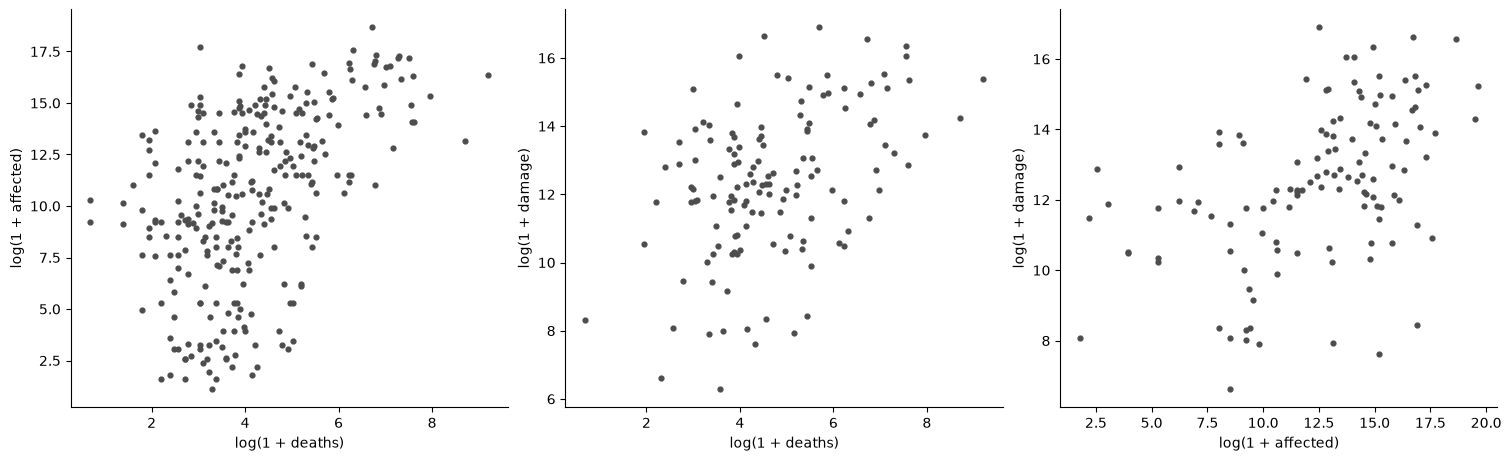

,events reporting,zeros,median of log(1 + value),correlation with log damage
deaths,424,0,3.87,0.43
affected,307,0,10.82,0.47
damage,139,0,12.51,1.00


In [5]:
log_indicators = np.log1p(record[list(INDICATORS)])

figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, (x_name, y_name) in zip(axes, [("deaths", "affected"), ("deaths", "damage"), ("affected", "damage")], strict=True):
    axis.scatter(log_indicators[x_name],
                 log_indicators[y_name],
                 s=12,
                 color="0.3")
    axis.set_xlabel(f"log(1 + {x_name})")
    axis.set_ylabel(f"log(1 + {y_name})")
plt.show()

pd.DataFrame({
    "events reporting": log_indicators.count(),
    "zeros": (record[list(INDICATORS)] == 0).sum(),
    "median of log(1 + value)": log_indicators.median(),
    "correlation with log damage": log_indicators.corr()["damage"],
}).round(2)

In [6]:
pd.concat([
    record.groupby("disaster_class").size().rename("events"),
    record.groupby("disaster_class")[list(INDICATORS)].count().add_prefix("reporting "),
    log_indicators.groupby(record["disaster_class"]).median().add_prefix("median log "),
], axis=1).round(1)

,events,reporting deaths,reporting affected,reporting damage,median log deaths,median log affected,median log damage
disaster_class,,,,,,,
Climatological,52,46,10,6,4.80,10.10,14.00
Hydrometeorological,400,378,297,133,3.80,10.80,12.30


Deaths, people affected and damage each correlate with the others at about 0.45 on the log scale, and their balance depends on the class of disaster. Within the climatological class, heat waves record deaths and little else, while droughts record hundreds of millions affected and few deaths. The model below therefore gives each count an intercept per class.

## Exposure

An event's counts are read against what stood near its center: the people within 50 km of the center atom, counted at the GHS-POP epoch nearest the event's year, and India's GDP per head in constant dollars that year, from the World Bank. Both enter on the log scale, as #214 found they must, and each is centered on its 2005 value, so a count's intercept is its level for an event at a center of 2005 typical exposure and 2005 income.

In [7]:
EXPOSURE_RADIUS_KM = 50.0
EXPOSURE_EPOCHS = tuple(epoch for epoch in POPULATION_EPOCHS if 1990 <= epoch <= 2025)
REFERENCE_YEAR = 2005

# Each atom's neighborhood is every atom whose center lies within the radius of its own, itself included.
neighborhoods = cKDTree(atom_xy).query_ball_point(atom_xy, r=EXPOSURE_RADIUS_KM * 1_000.0)
neighbor_rows = np.repeat(np.arange(n_atoms), [len(found) for found in neighborhoods])
neighbor_columns = np.concatenate(neighborhoods)
log_exposure_by_epoch = np.stack([
    np.log1p(np.bincount(neighbor_rows, weights=population_on_cells(grid, epoch, CACHE_DIR)[neighbor_columns], minlength=n_atoms))
    for epoch in EXPOSURE_EPOCHS
])
reference_epoch = EXPOSURE_EPOCHS.index(REFERENCE_YEAR)
exposure_center = np.median(log_exposure_by_epoch[reference_epoch])
centered_exposure = log_exposure_by_epoch - exposure_center

log_income = (load_wb_data(CACHE_DIR)
              .filter(pl.col("country_code") == ISO)
              .select("year", pl.col("gdp_per_cap_usd").log().alias("log_income"))
              .to_pandas()
              .set_index("year")["log_income"])
centered_income = log_income - log_income.loc[REFERENCE_YEAR]

pd.Series({
    "atoms per neighborhood, median": np.median([len(found) for found in neighborhoods]),
    f"people within {EXPOSURE_RADIUS_KM:.0f} km of an atom in {REFERENCE_YEAR}, median": np.expm1(exposure_center),
    f"centered log exposure in {REFERENCE_YEAR}, 1st to 99th percentile": np.percentile(centered_exposure[reference_epoch], [1, 99]).round(2),
    f"log GDP per head, {FIRST_YEAR} and {LAST_YEAR} against {REFERENCE_YEAR}": centered_income.loc[[FIRST_YEAR, LAST_YEAR]].round(2).to_list(),
})

atoms per neighborhood, median                                    9.00
people within 50 km of an atom in 2005, median              1298280.62
centered log exposure in 2005, 1st to 99th percentile    [-7.85, 1.85]
log GDP per head, 1990 and 2023 against 2005             [-0.57, 0.86]
dtype: object

## The model

Events happen whether or not EM-DAT records them. The model describes every event, with its center, its class, the size of its hazard and what it did to the people and assets near it, and treats EM-DAT as a record truncated at its entry thresholds. Where an event starts and what it cost are then two parts of one generative story, and the record's selection on size is part of the likelihood.

### Events

Event centers fall on atom $a$ in year $t$ as a Poisson process with rate

$$\lambda_{a,t} = \exp\left(\beta_0 + X_a^\top \beta + f(a) + u_{\mathrm{ADM1}(a)} + \eta_t\right),$$

01's hazard covariates and HSGP field $f$, an offset $u$ per state, and a year effect $\eta_t = g(t) + \tau \epsilon_t$ acting on all events: a smooth curve $g$ over years and a frailty per year, $\epsilon_t \sim \operatorname{Normal}(0, 1)$, which carries the variation between years the curve leaves. 01's district offsets are left out: an event is placed only to the units it names, mostly whole states, so structure below a state is the field's or no one's, and districts of a few atoms took extreme offsets that only the state and country events covering them informed. Each event draws

$$k_e \sim \operatorname{Categorical}(\rho), \qquad H_e \sim \operatorname{Normal}(0, 1),$$

a class and a hazard size, neither of which depends on where it struck.

### What an event does

Its three counts read the hazard against the exposure at its center. With $x_{a,t}$ the centered log population within 50 km of atom $a$ at the epoch nearest year $t$, and $g_t$ the centered log GDP per head,

$$y_{ej} \mid H_e, a \sim \operatorname{Normal}\left(\mu_{ej} = \alpha_{j,k_e} + b_j H_e + e_j\, x_{a,t_e} + v_j\, g_{t_e},\ s_j\right), \qquad j \in \{\text{deaths}, \text{affected}, \text{damage}\},$$

on $\log(1 + \text{value})$. Each count has an intercept per class, a positive loading $b_j$ on the hazard, its own exposure elasticity $e_j$ and its own income coefficient $v_j$. People affected can scale with the people present, damage with people and income, and deaths can fall as income rises, each at its own rate. The hazard is standardized, so its level and scale are fixed by its prior and no intercept can trade off against it.

### Entering the record

EM-DAT records an event that kills at least 10 people or affects at least 100, or, with probability $\delta$, one for which an emergency is declared. A recorded event is reported at level $L_e \sim \operatorname{Categorical}(\pi)$, names units whose union $U_e$ holds its center, and has its damage written down with probability $\operatorname{logit}^{-1}(c_0 + c_1 (\mu_{e,\text{damage}} - 12.5))$, $c_1 \geq 0$. Deaths or affected counts missing from a recorded event are missing at random given its hazard and center.

### The record as a thinned point process

Recorded events are the Poisson process thinned by the chance of entering the record,

$$P(R \mid a, k, t) = \delta + (1 - \delta) \int \left[1 - \Phi\left(\frac{\log 11 - \mu_{\text{deaths}}}{s_{\text{deaths}}}\right) \Phi\left(\frac{\log 101 - \mu_{\text{affected}}}{s_{\text{affected}}}\right)\right] \phi(H)\, dH,$$

computed by Gauss-Hermite quadrature over the hazard. That probability replaces 01's naming curve: detection rises with population because an event in an empty district rarely affects 100 people, and the model now says so through the exposure elasticities. The share of events below both thresholds, which the Laos model and 01 could not identify, is set by the fitted count distributions, and rests on their normal shape below the thresholds, which the record does not see.

The record's likelihood is the Poisson process's own, and it is the one term with no standard distribution, so it enters as a `CustomDist` per year,

$$\sum_t \left[-\Lambda_t + \sum_{e \in t} \left(\eta_t + \log \textstyle\sum_{a \in U_e} \lambda_a\right)\right], \qquad \Lambda_t = e^{\eta_t} \sum_{a, k} \lambda_a\, \rho_k\, P(R \mid a, k, t).$$

The expected recorded events enter with a minus sign, each recorded event adds the log rate of all events in its union, and its marks carry the rest of its intensity.

### The marks

Everything else is a standard distribution. The class and level are observed categoricals. The hazard is a latent normal per event. The center within the union is a categorical over the union's exposure bins, with probabilities proportional to the rate in each, marginalized out by `pymc_extras`, which needs every variable depending on a center to cover all of that center's events, so events are grouped by which counts they report. The counts are observed normals, damage reporting an observed Bernoulli, and for the ten events no reported count carries past a threshold, entering the record an observed Bernoulli through a missing count crossing or a declaration.

### What the fit gives the PGR workflow

The posterior describes every event, recorded or not. Simulating years forward from it, centers from $\lambda$, a class, a hazard, and damage at the exposure and income of the target year, gives annual damage for India, each state and each atom from one set of draws. Changing exposure moves damage through the elasticities while the hazard distribution stays fixed, which is the separation return-period curves under growth need.

In [8]:
HSGP_BOUNDARY_FACTOR = 4.0
HSGP_BASIS_PER_AXIS = 50
YEAR_BOUNDARY_FACTOR = 1.5
YEAR_BASIS = 20
OFFSET_SD_PRIOR = 0.5
# State offsets only. District offsets competed with the field for structure below the size of a union, and districts of one to five atoms,
# informed only by the state and country events covering them, took offsets above 1 and a fifth of the fitted rate in the recovery.
OFFSET_LEVELS = ("ADM1",)
# A prior guess at India's events per year, recorded or not, which fixes where the rate's intercept sits. Summed over atoms,
# the covariates, field and offsets inflate the prior's typical total about eightfold, to a few hundred a year.
PRIOR_EVENTS_PER_YEAR = 25
# A fifth of a log unit, a factor of 1.22 in the people near a center.
EXPOSURE_BIN_WIDTH = 0.2
QUADRATURE_NODES = 20
# EM-DAT's entry thresholds, on log(1 + count): at least 10 deaths or at least 100 people affected.
ENTRY_THRESHOLDS = {"deaths": np.log1p(10), "affected": np.log1p(100)}
# Log damage, in thousands of dollars, of a typical event with a damage figure: about $270 million.
DAMAGE_REFERENCE = 12.5

years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
YEARS = len(years)

exposure_edges = np.arange(np.floor(centered_exposure.min() / EXPOSURE_BIN_WIDTH) * EXPOSURE_BIN_WIDTH,
                           centered_exposure.max() + EXPOSURE_BIN_WIDTH,
                           EXPOSURE_BIN_WIDTH)
exposure_bin_centers = (exposure_edges[:-1] + exposure_edges[1:]) / 2
n_exposure_bins = len(exposure_bin_centers)


def exposure_bin(values):
    """The exposure bin of each centered log exposure."""
    return np.clip(np.digitize(values, exposure_edges) - 1, 0, n_exposure_bins - 1)


# All of India's atoms by exposure bin at each epoch, for the yearly totals; each year reads its nearest epoch.
n_epochs = len(EXPOSURE_EPOCHS)
epoch_bins = Aggregation(units=tuple(f"epoch {epoch} bin {bin_index}" for epoch in EXPOSURE_EPOCHS for bin_index in range(n_exposure_bins)),
                         rows=np.concatenate([index * n_exposure_bins + exposure_bin(centered_exposure[index]) for index in range(n_epochs)]),
                         columns=np.tile(np.arange(n_atoms), n_epochs),
                         weights=np.ones(n_epochs * n_atoms),
                         n_cells=n_atoms)
year_epoch = np.abs(years[:, None] - np.array(EXPOSURE_EPOCHS)[None, :]).argmin(axis=1)
year_income = centered_income.loc[years].to_numpy()

# Probabilists' Gauss-Hermite nodes and weights, for the share of all events, recorded or not, that enters the record.
hazard_nodes, hazard_weights = np.polynomial.hermite_e.hermegauss(QUADRATURE_NODES)
hazard_weights = hazard_weights / hazard_weights.sum()


def union_atoms(named):
    """The atoms an event's named units overlap, at whichever levels it names."""
    return np.unique(np.concatenate([overlaps[level]["atom"][overlaps[level]["unit"].isin(found)].to_numpy() for level, found in named.items()]))


def reporting_groups(reported, crossed):
    """
    The record's events grouped by which counts they report and whether a reported count crosses a threshold.

    Every variable that depends on an event's center then covers all of its group's events, which is what marginalizing the center needs.
    """
    patterns, group_of_event = np.unique(np.column_stack([reported, crossed]), axis=0, return_inverse=True)

    return [{"name": "_".join([name for name, present in zip(INDICATORS, pattern[:-1], strict=True) if present] or ["none"]) + ("" if pattern[-1] else "_below"),
             "events": np.flatnonzero(group_of_event == index),
             "reported": pattern[:-1].astype(bool),
             "crossed": bool(pattern[-1])}
            for index, pattern in enumerate(patterns)]


def record_arrays(named, level, disaster_class, year, log_values, labels):
    """
    Everything the likelihood reads from a record of events.

    Parameters
    ----------
    named : sequence of dict
        Each event's named units, as positions into units[level], keyed by level.
    level : sequence of str
        The level each event is reported at, one of LEVELS.
    disaster_class : sequence of str
        Each event's class, one of CLASSES.
    year : ndarray
        Each event's calendar year.
    log_values : ndarray
        Each event's log(1 + count) for deaths, affected and damage, one column each in INDICATORS order, NaN where not reported.
    labels : sequence
        Each event's label, for the event coordinate.

    Returns
    -------
    arrays : dict
        The record's per-event arrays, its (event, exposure bin) pairs and their aggregation, its reporting groups, and its recorded events per year.
    """
    year_index = np.asarray(year) - FIRST_YEAR
    epoch = year_epoch[year_index]
    atoms_by_event = [union_atoms(found) for found in named]
    bins_by_event = [exposure_bin(centered_exposure[event_epoch_index, event_atoms]) for event_atoms, event_epoch_index in zip(atoms_by_event, epoch, strict=True)]
    pair_keys = [np.unique(bins) for bins in bins_by_event]
    pair_offset = np.concatenate([[0], np.cumsum([len(keys) for keys in pair_keys])[:-1]])
    pair_event = np.repeat(np.arange(len(named)), [len(keys) for keys in pair_keys])
    pair_bin = np.concatenate(pair_keys)
    reported = ~np.isnan(log_values)
    crossed = np.column_stack([np.where(reported[:, list(INDICATORS).index(name)], log_values[:, list(INDICATORS).index(name)], -np.inf) >= threshold
                               for name, threshold in ENTRY_THRESHOLDS.items()]).any(axis=1)

    return {
        "labels": np.asarray(labels),
        "class": pd.Series(np.arange(len(CLASSES)), index=CLASSES).loc[list(disaster_class)].to_numpy(),
        "year": year_index,
        "level": pd.Series(np.arange(len(LEVELS)), index=LEVELS).loc[list(level)].to_numpy(),
        "pair_event": pair_event,
        "pair_bin": pair_bin,
        "pairs": Aggregation(units=tuple(f"event {event} bin {bin_index}" for event, bin_index in zip(pair_event, pair_bin, strict=True)),
                             rows=np.concatenate([offset + np.searchsorted(keys, bins) for offset, keys, bins in zip(pair_offset, pair_keys, bins_by_event, strict=True)]),
                             columns=np.concatenate(atoms_by_event),
                             weights=np.ones(sum(len(event_atoms) for event_atoms in atoms_by_event)),
                             n_cells=n_atoms),
        "values": np.nan_to_num(log_values),
        "reported": reported,
        "groups": reporting_groups(reported, crossed),
        "annual": np.bincount(year_index, minlength=YEARS),
    }


observed = record_arrays(named=record["named"],
                         level=record["level"],
                         disaster_class=record["disaster_class"],
                         year=record["year"].to_numpy(),
                         log_values=log_indicators[list(INDICATORS)].to_numpy(),
                         labels=record["DisNo."])

COORDS = {
    "covariate": list(COVARIATE_NAMES),
    "atom": np.arange(n_atoms),
    "level": list(LEVELS),
    "year": years,
    "class": CLASSES,
    "indicator": list(INDICATORS),
    **{level: units[level]["gid"].to_list() for level in OFFSET_LEVELS},
}

pd.Series({group["name"]: len(group["events"]) for group in observed["groups"]} | {"exposure bins": n_exposure_bins}, name="events")

none_below                  5
damage_below                1
affected                   18
affected_damage             4
deaths_below                3
deaths                    119
deaths_damage              17
deaths_affected_below       1
deaths_affected           167
deaths_affected_damage    117
exposure bins              88
Name: events, dtype: int64

In [20]:
DEATHS, AFFECTED, DAMAGE = range(len(INDICATORS))


def scale_prior(name, mean):
    """
    A scale whose prior density vanishes at zero, a Gamma with shape 2 and the given mean.

    Shape 2 is the boundary-avoiding prior of Chung et al. (2013, doi:10.1007/s11336-013-9328-2): linear at zero, so the posterior cannot
    pile up there, while leaving a scale near zero reachable when the data ask for it.
    """
    return pm.Gamma(name, alpha=2.0, beta=2.0 / mean)


def hsgp_field(amplitude, lengthscale):
    """The field at every atom, a Hilbert space approximation to a Matern 3/2 GP."""
    gp = pm.gp.HSGP(m=[HSGP_BASIS_PER_AXIS, HSGP_BASIS_PER_AXIS],
                    c=HSGP_BOUNDARY_FACTOR,
                    cov_func=amplitude**2 * pm.gp.cov.Matern32(input_dim=2, ls=lengthscale))

    return gp.prior("field", X=atom_centroids, dims="atom")


def latent_log_rate():
    """The log rate of event centers per atom and year, recorded or not, before the year effect, built inside the current model."""
    intercept = pm.Normal("intercept",
                          mu=np.log(PRIOR_EVENTS_PER_YEAR / n_atoms),
                          sigma=1.0)
    slopes = pm.Normal("slopes",
                       mu=0.0,
                       sigma=1.0,
                       dims="covariate")

    # Mode at 0.1 of the domain, with a tail out past half its width.
    field_lengthscale = pm.InverseGamma("field_lengthscale",
                                        alpha=3.0,
                                        beta=0.4)
    field_amplitude = scale_prior("field_amplitude", mean=0.8)
    field = hsgp_field(field_amplitude, field_lengthscale)

    offset_part = 0.0
    for level in OFFSET_LEVELS:
        offset_sd = scale_prior(f"{level}_offset_sd", mean=OFFSET_SD_PRIOR)
        standard = pm.Normal(f"{level}_offset_standard",
                             mu=0.0,
                             sigma=1.0,
                             dims=level)
        offsets = pm.Deterministic(f"{level}_offset", offset_sd * standard, dims=level)
        offset_part = offset_part + offsets[unit_of_atom[level]]

    return pm.Deterministic("log_rate",
                            intercept + pm.math.dot(covariates, slopes) + field + offset_part,
                            dims="atom")


def year_effect():
    """The year effect on the rate of all events: a smooth curve over years plus a frailty per year."""
    # Mode at 5 years, so the curve follows changes over a few years and leaves single years to the frailty.
    year_lengthscale = pm.InverseGamma("year_lengthscale",
                                       alpha=3.0,
                                       beta=20.0)
    year_amplitude = scale_prior("year_amplitude", mean=0.4)
    gp = pm.gp.HSGP(m=[YEAR_BASIS],
                    c=YEAR_BOUNDARY_FACTOR,
                    cov_func=year_amplitude**2 * pm.gp.cov.Matern52(input_dim=1, ls=year_lengthscale))
    smooth = gp.prior("year_smooth", X=years[:, None].astype(float), dims="year")
    frailty_sd = scale_prior("frailty_sd", mean=0.4)
    frailty = pm.Normal("frailty_standard", mu=0.0, sigma=1.0, dims="year")

    return pm.Deterministic("year_effect", smooth + frailty_sd * frailty, dims="year")


def indicator_parameters():
    """How deaths, people affected and damage read an event's hazard against the exposure and income where it struck."""
    return {
        # A typical event, recorded or not, sits just below EM-DAT's thresholds of 10 deaths and 100 affected.
        "intercept": pm.Normal("indicator_intercept",
                               mu=np.array([[1.0], [3.0], [10.0]]),
                               sigma=np.array([[1.5], [2.0], [3.0]]),
                               dims=("indicator", "class")),
        "loading": pm.HalfNormal("loading", sigma=2.0, dims="indicator"),
        "elasticity": pm.Normal("exposure_elasticity", mu=0.0, sigma=1.0, dims="indicator"),
        "income": pm.Normal("income_coefficient", mu=0.0, sigma=1.0, dims="indicator"),
        # Mean 2, mode 1.33 on log(1 + count).
        "sd": pm.InverseGamma("indicator_sd", alpha=5.0, beta=8.0, dims="indicator"),
    }


def normal_cdf(z):
    """The standard normal distribution function."""
    return 0.5 * pt.erfc(-z / np.sqrt(2.0))


def below_threshold(mean, sd, name):
    """The probability that an indicator with this mean and sd falls below EM-DAT's entry threshold for it."""
    return normal_cdf((ENTRY_THRESHOLDS[name] - mean) / sd)


def recording_probability(below, declaration):
    """The probability of entering the record, given the probability that every count still in question falls below its threshold."""
    return declaration + (1.0 - declaration) * (1.0 - below)


def expected_recorded_per_year(rate, parameters, class_probability, declaration):
    """Each year's expected recorded events before the year effect: the rate by exposure bin, times each class's chance there of entering the record."""
    def indicator_mean(indicator):
        # Over (class, year, bin, hazard node).
        return (parameters["intercept"][indicator][:, None, None, None]
                + parameters["loading"][indicator] * hazard_nodes[None, None, None, :]
                + parameters["elasticity"][indicator] * exposure_bin_centers[None, None, :, None]
                + parameters["income"][indicator] * year_income[None, :, None, None])

    below = (below_threshold(indicator_mean(DEATHS), parameters["sd"][DEATHS], "deaths")
             * below_threshold(indicator_mean(AFFECTED), parameters["sd"][AFFECTED], "affected"))
    recorded_share = (recording_probability(below, declaration) * hazard_weights).sum(axis=-1)
    rate_by_bin = epoch_bins.aggregate_symbolic(rate).reshape((n_epochs, n_exposure_bins))[year_epoch]

    return (class_probability[:, None, None] * recorded_share * rate_by_bin[None]).sum(axis=(0, 2))


def poisson_process_logp(count, recorded_per_year, effect, union_log_rate):
    """
    Log likelihood of a year's recorded events under the thinned Poisson process, with each event's center coarsened to its named units.

    The year's expected recorded events enter with a minus sign, and each recorded event adds the year effect and the log rate of all events
    in its union. The marks carry the rest of each event's intensity.
    """
    return -pt.exp(effect) * recorded_per_year + count * effect + union_log_rate


def build_joint_model(data):
    """Every event's center, class, hazard and counts, with the record ``data`` the events past EM-DAT's entry thresholds."""
    groups = data["groups"]
    coords = COORDS | {"event": data["labels"]} | {f"event_{group['name']}": data["labels"][group["events"]] for group in groups}

    with pm.Model(coords=coords) as model:
        rate = pm.math.exp(latent_log_rate())
        effect = year_effect()
        parameters = indicator_parameters()
        class_probability = pm.Dirichlet("class_probability", a=np.ones(len(CLASSES)), dims="class")
        level_probability = pm.Dirichlet("level_probability", a=np.ones(len(LEVELS)), dims="level")
        # A sub-threshold event enters by declaration rarely; the prior puts the floor near one in a thousand.
        declaration_logit = pm.Normal("declaration_logit", mu=-7.0, sigma=2.0)
        declaration = pm.Deterministic("declaration_probability", pm.math.invlogit(declaration_logit))
        reporting_intercept = pm.Normal("reporting_intercept", mu=0.0, sigma=1.5)
        # Events with a damage figure are larger on every other measure, so larger damage is no less likely to be written down.
        reporting_slope = pm.HalfNormal("reporting_slope", sigma=1.0)

        # Where recorded events land and how many there are each year, as the thinned Poisson process.
        bin_rate = pt.set_subtensor(pt.zeros((len(data["labels"]), n_exposure_bins))[data["pair_event"], data["pair_bin"]],
                                    data["pairs"].aggregate_symbolic(rate))
        union_rate = bin_rate.sum(axis=1)
        recorded_per_year = expected_recorded_per_year(rate, parameters, class_probability, declaration)
        pm.Deterministic("expected_recorded", recorded_per_year * pt.exp(effect), dims="year")
        pm.CustomDist("recorded_events",
                      recorded_per_year,
                      effect,
                      pt.zeros(YEARS)[data["year"]].inc(pt.log(union_rate)),
                      logp=poisson_process_logp,
                      observed=data["annual"],
                      dims="year")

        # Each recorded event's marks.
        pm.Categorical("event_class", p=class_probability, observed=data["class"], dims="event")
        pm.Categorical("event_level", p=level_probability, observed=data["level"], dims="event")
        # A bin the union does not reach carries no weight; the floor keeps its log finite.
        center_probability = (bin_rate / union_rate[:, None] + 1e-12) / (1.0 + n_exposure_bins * 1e-12)

        marginalized = []
        for group in groups:
            events, name, dim = group["events"], group["name"], f"event_{group['name']}"
            center = pm.Categorical(f"center_{name}", p=center_probability[events], dims=dim)
            # The hazard is a standard normal on the quadrature nodes the recorded share uses, summed out with the center. Sampled per
            # event, it lets an indicator's sd collapse while the hazards copy that indicator.
            hazard_node = pm.Categorical(f"hazard_node_{name}", p=hazard_weights, dims=dim)
            hazard = pt.as_tensor(hazard_nodes)[hazard_node]
            marginalized.extend([center.name, hazard_node.name])
            means = [parameters["intercept"][indicator][data["class"][events]]
                     + parameters["loading"][indicator] * hazard
                     + parameters["elasticity"][indicator] * pt.as_tensor(exposure_bin_centers)[center]
                     + parameters["income"][indicator] * year_income[data["year"][events]]
                     for indicator in range(len(INDICATORS))]

            # Observed values go in as Data so that groups observing identical arrays keep separate value variables when the centers are marginalized.
            for indicator, count_name in enumerate(INDICATORS):
                if group["reported"][indicator]:
                    pm.Normal(f"log_{count_name}_{name}",
                              mu=means[indicator],
                              sigma=parameters["sd"][indicator],
                              observed=pm.Data(f"log_{count_name}_{name}_data", data["values"][events, indicator], dims=dim),
                              dims=dim)
            pm.Bernoulli(f"damage_reported_{name}",
                         logit_p=reporting_intercept + reporting_slope * (means[DAMAGE] - DAMAGE_REFERENCE),
                         observed=pm.Data(f"damage_reported_{name}_data", np.full(len(events), int(group["reported"][DAMAGE])), dims=dim),
                         dims=dim)

            # An event past a threshold on a reported count is in the record for certain. Otherwise it entered through a missing count or a declaration.
            if not group["crossed"]:
                below_missing = 1.0
                for indicator, count_name in [(DEATHS, "deaths"), (AFFECTED, "affected")]:
                    if not group["reported"][indicator]:
                        below_missing = below_missing * below_threshold(means[indicator], parameters["sd"][indicator], count_name)
                pm.Bernoulli(f"entered_record_{name}",
                             p=recording_probability(below_missing, declaration),
                             observed=pm.Data(f"entered_record_{name}_data", np.ones(len(events), dtype=int), dims=dim),
                             dims=dim)

    return pmx.marginalize(model, marginalized)


joint_model = build_joint_model(observed)

pd.Series({"free parameters": sum(value.size for value in joint_model.initial_point().values())})

free parameters    2630
dtype: int64

## Prior predictive

How many recorded events over 34 years the priors allow, and what deaths, people affected and damage they allow per event, against the record.

Sampling: [ADM1_offset_sd, ADM1_offset_standard, class_probability, declaration_logit, exposure_elasticity, field_amplitude, field_hsgp_coeffs, field_lengthscale, frailty_sd, frailty_standard, income_coefficient, indicator_intercept, indicator_sd, intercept, loading, reporting_intercept, reporting_slope, slopes, year_amplitude, year_lengthscale, year_smooth_hsgp_coeffs]


  0%|          | 0/300 [00:00<?, ?it/s]

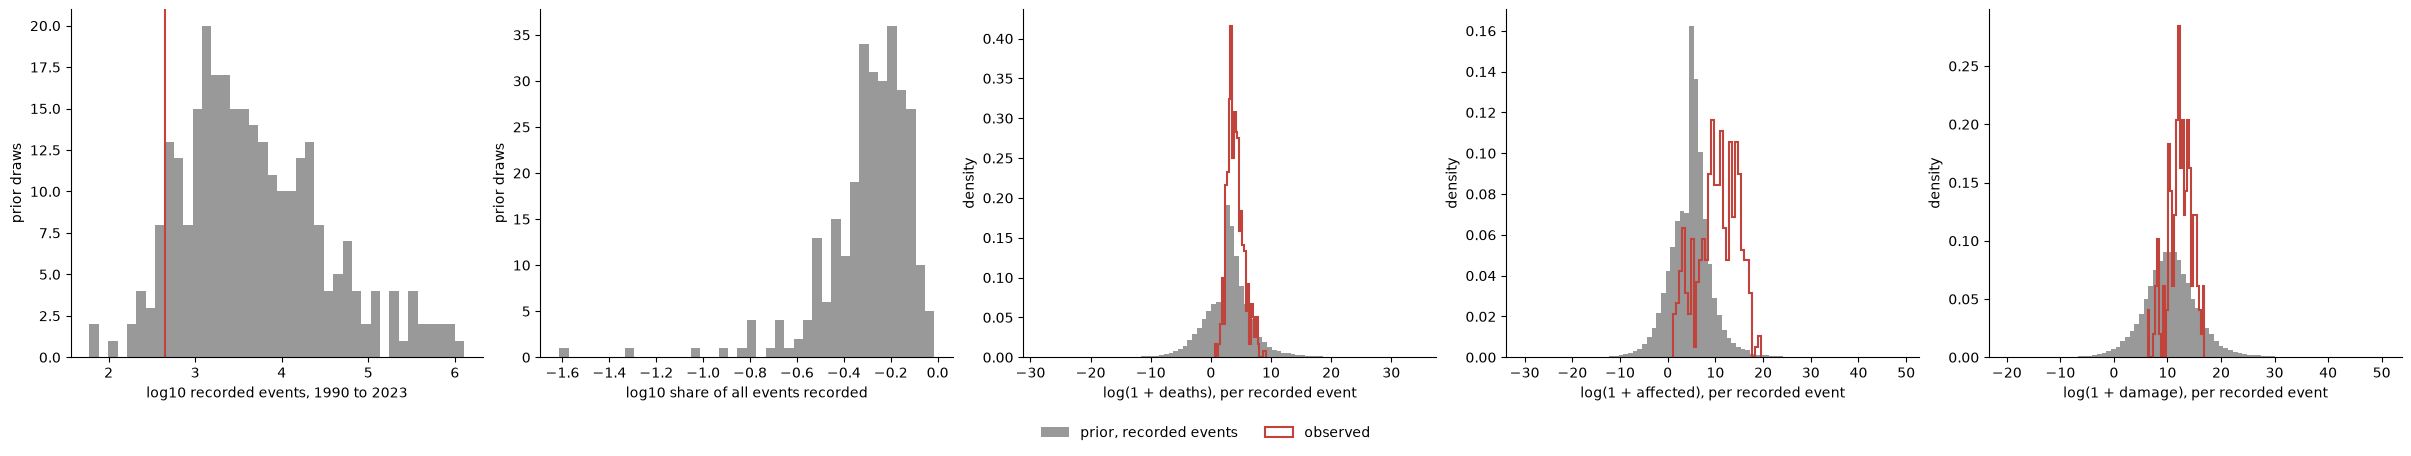

draws simulated                                             287.00
draws within a factor of 3 of 452 recorded events            72.00
share reporting damage, median over draws (observed 0.31)     0.34
dtype: float64

In [17]:
PRIOR_DRAWS = 300
# A draw expecting more events than this over the record is too far in the prior's tail to simulate event by event.
SIMULATION_EVENT_LIMIT = 2_000_000
OBSERVED_COLOR = "#c1443c"
PRIOR_COLOR = "0.6"
SIMULATED_VARIABLES = ["log_rate", "year_effect", "indicator_intercept", "loading", "exposure_elasticity", "income_coefficient",
                       "indicator_sd", "class_probability", "declaration_probability", "reporting_intercept", "reporting_slope"]


def simulate_events(draw, rng):
    """
    Every event over the record from one parameter draw, with its center, class, hazard, counts, and whether EM-DAT records it.

    Returns None when the draw expects more than SIMULATION_EVENT_LIMIT events. The year effect already carries each year's frailty, so a
    year's count is Poisson given the draw.
    """
    rate = np.exp(draw["log_rate"][None, :] + draw["year_effect"][:, None])
    if rate.sum() > SIMULATION_EVENT_LIMIT:
        return None

    counts = rng.poisson(rate)
    year_index, atom = np.nonzero(counts)
    repeats = counts[year_index, atom]
    year_index, atom = np.repeat(year_index, repeats), np.repeat(atom, repeats)
    n_simulated = len(atom)

    event_class_simulated = rng.choice(len(CLASSES), size=n_simulated, p=draw["class_probability"])
    hazard = rng.standard_normal(n_simulated)
    means = (draw["indicator_intercept"][:, event_class_simulated]
             + draw["loading"][:, None] * hazard[None, :]
             + draw["exposure_elasticity"][:, None] * centered_exposure[year_epoch[year_index], atom][None, :]
             + draw["income_coefficient"][:, None] * year_income[year_index][None, :])
    values = means + draw["indicator_sd"][:, None] * rng.standard_normal(means.shape)
    recorded = ((values[DEATHS] >= ENTRY_THRESHOLDS["deaths"])
                | (values[AFFECTED] >= ENTRY_THRESHOLDS["affected"])
                | (rng.random(n_simulated) < draw["declaration_probability"]))
    damage_logit = draw["reporting_intercept"] + draw["reporting_slope"] * (means[DAMAGE] - DAMAGE_REFERENCE)
    damage_written = rng.random(n_simulated) < 1.0 / (1.0 + np.exp(-damage_logit))

    return {"year": year_index, "atom": atom, "class": event_class_simulated, "hazard": hazard, "values": values.T, "recorded": recorded,
            "damage_reported": damage_written}


with joint_model:
    prior = pm.sample_prior_predictive(draws=PRIOR_DRAWS,
                                       var_names=SIMULATED_VARIABLES,
                                       random_seed=SEED)
prior_draws = prior.prior.isel(chain=0)
prior_rng = np.random.default_rng(SEED)

prior_summary_rows = []
prior_recorded_values = []
for draw_index in tqdm(range(PRIOR_DRAWS)):
    prior_simulated = simulate_events({name: prior_draws[name].isel(draw=draw_index).to_numpy() for name in SIMULATED_VARIABLES}, prior_rng)
    if prior_simulated is None:
        continue
    prior_recorded = prior_simulated["recorded"]
    prior_summary_rows.append({"all events": len(prior_recorded),
                               "recorded events": int(prior_recorded.sum()),
                               "share reporting damage": prior_simulated["damage_reported"][prior_recorded].mean() if prior_recorded.any() else np.nan})
    prior_recorded_values.append(prior_simulated["values"][prior_recorded][:200])
prior_summaries = pd.DataFrame(prior_summary_rows)
prior_recorded_values = np.concatenate(prior_recorded_values)
observed_total = observed["annual"].sum()
observed_damage_share = observed["reported"][:, DAMAGE].mean()

figure, axes = plt.subplots(1, 5, figsize=(24, 4), constrained_layout=True)
# Event totals span orders of magnitude under the prior, so they are compared as log10 of one plus the count.
axes[0].hist(np.log10(prior_summaries["recorded events"] + 1),
             bins=40,
             color=PRIOR_COLOR)
axes[0].axvline(np.log10(observed_total + 1),
                color=OBSERVED_COLOR)
axes[0].set_xlabel(f"log10 recorded events, {FIRST_YEAR} to {LAST_YEAR}")
axes[1].hist(np.log10((prior_summaries["recorded events"] + 1) / (prior_summaries["all events"] + 1)),
             bins=40,
             color=PRIOR_COLOR)
axes[1].set_xlabel("log10 share of all events recorded")
for axis in axes[:2]:
    axis.set_ylabel("prior draws")

for axis, name in zip(axes[2:], INDICATORS, strict=True):
    column = list(INDICATORS).index(name)
    axis.hist(prior_recorded_values[:, column],
              bins=80,
              density=True,
              color=PRIOR_COLOR,
              label="prior, recorded events")
    axis.hist(observed["values"][observed["reported"][:, column], column],
              bins=30,
              density=True,
              histtype="step",
              color=OBSERVED_COLOR,
              linewidth=1.5,
              label="observed")
    axis.set_xlabel(f"log(1 + {name}), per recorded event")
    axis.set_ylabel("density")

handles, labels = axes[2].get_legend_handles_labels()
figure.legend(handles=handles,
              labels=labels,
              loc="lower center",
              bbox_to_anchor=(0.5, -0.12),
              ncol=len(labels),
              frameon=False)
plt.show()

pd.Series({
    "draws simulated": len(prior_summaries),
    f"draws within a factor of 3 of {observed_total} recorded events": int((np.abs(np.log((prior_summaries["recorded events"] + 1) / (observed_total + 1))) < np.log(3)).sum()),
    f"share reporting damage, median over draws (observed {observed_damage_share:.2f})": prior_summaries["share reporting damage"].median(),
}).round(2)

The model's event term is a density of the record, with no way to draw one, so the prior predictive draws every event from each prior draw by simulation: centers from the rate, a class, a hazard, three counts at the center's exposure and the year's income, entry by EM-DAT's thresholds or a declaration, and a damage figure written down or not. The record's 452 events sit in the lower part of the prior's spread over four orders of magnitude, with 72 of 287 simulated draws within a factor of three of it. The median draw has about 220 events a year, of which 55% enter the record, 24% to 81% over the middle 90% of draws. A recorded event's deaths and damage under the prior cover the observed range. Its people affected pile up just past the threshold of 100, where the record has a second mode near a quarter of a million, which the prior allows but does not favor.

## Recovery on a simulated record

Does the fit recover the parameters of a record simulated from the model? The truth is the first of 300 prior draws whose record looks like India's: a recorded total within a factor of two of 452, and a share of recorded events reporting damage between 0.15 and 0.6. The simulator draws every event from that draw, records those past the thresholds or declared, and writes each recorded event down the way the likelihood reads one. Its level comes from the draw's level probabilities. A subnational event names its center's unit and that unit's nearest neighbors at the same level, as many units as a real event at that level names, drawn from the record, which is 01's naming step. Deaths and affected go missing at random at the record's rates, 6% and 32%, and damage goes missing by the simulated reporting model. The whole model is then fitted to that record, so the recovery tests the coupling between where an event was and what it cost along with everything else.

In [21]:
RECOVERY_CANDIDATES = 300
SUBNATIONAL_LEVELS = ("ADM2", "ADM1")
GLOBAL_VARIABLES = ["intercept", "slopes", "field_amplitude", "field_lengthscale", "ADM1_offset_sd", "year_amplitude", "year_lengthscale",
                    "frailty_sd", "class_probability", "level_probability", "declaration_logit", "indicator_intercept", "loading",
                    "exposure_elasticity", "income_coefficient", "indicator_sd", "reporting_intercept", "reporting_slope"]
missing_share = {name: 1.0 - observed["reported"][:, list(INDICATORS).index(name)].mean() for name in ("deaths", "affected")}

# 01's naming step: a subnational event names its center's unit and that unit's nearest neighbors, as many units as a real event at its level names.
union_sizes = {level: np.unique([len(named[level]) for named, reported in zip(record["named"], record["level"], strict=True) if reported == level], return_counts=True)
               for level in SUBNATIONAL_LEVELS}
unit_xy = {level: np.column_stack([centers.x, centers.y]) for level, centers in ((level, units[level].to_crs(PROJECTED_CRS).geometry.centroid) for level in SUBNATIONAL_LEVELS)}
nearest_units = {level: np.argsort(np.linalg.norm(unit_xy[level][:, None] - unit_xy[level][None], axis=2), axis=1) for level in SUBNATIONAL_LEVELS}


def name_units(atom, level, rng):
    """The units a recorded event centered at ``atom`` and reported at ``level`` names."""
    if level == "ADM0":
        return {"ADM0": (0,)}

    sizes, counts = union_sizes[level]
    size = rng.choice(sizes, p=counts / counts.sum())

    return {level: tuple(sorted(nearest_units[level][int(unit_of_atom[level][atom]), :size].tolist()))}


with joint_model:
    candidates = pm.sample_prior_predictive(draws=RECOVERY_CANDIDATES,
                                            var_names=sorted(set(GLOBAL_VARIABLES) | set(SIMULATED_VARIABLES)),
                                            random_seed=SEED + 1)
candidate_draws = candidates.prior.isel(chain=0)
recovery_rng = np.random.default_rng(SEED + 1)

for chosen_draw in range(RECOVERY_CANDIDATES):
    truth = candidate_draws.isel(draw=chosen_draw)
    simulated = simulate_events({name: truth[name].to_numpy() for name in SIMULATED_VARIABLES}, recovery_rng)
    if simulated is None:
        continue
    recorded_index = np.flatnonzero(simulated["recorded"])
    damage_share = simulated["damage_reported"][recorded_index].mean() if len(recorded_index) else 0.0
    if abs(np.log(max(len(recorded_index), 1) / observed_total)) < np.log(2.0) and 0.15 < damage_share < 0.6:
        break

simulated_levels = recovery_rng.choice(LEVELS, size=len(recorded_index), p=truth["level_probability"].to_numpy())
simulated_log_values = simulated["values"][recorded_index].copy()
for name, share in missing_share.items():
    simulated_log_values[recovery_rng.random(len(recorded_index)) < share, list(INDICATORS).index(name)] = np.nan
simulated_log_values[~simulated["damage_reported"][recorded_index], DAMAGE] = np.nan
simulated_named = [name_units(atom, level, recovery_rng) for atom, level in zip(simulated["atom"][recorded_index], simulated_levels, strict=True)]

simulated_record = record_arrays(named=simulated_named,
                                 level=simulated_levels,
                                 disaster_class=np.array(CLASSES)[simulated["class"][recorded_index]],
                                 year=FIRST_YEAR + simulated["year"][recorded_index],
                                 log_values=simulated_log_values,
                                 labels=np.arange(len(recorded_index)))
recovery_model = build_joint_model(simulated_record)

pd.Series({
    "chosen prior draw": chosen_draw,
    "all events in the draw": len(simulated["recorded"]),
    "recorded events": len(recorded_index),
    "share reporting damage": round(float(damage_share), 2),
    "recorded events per level": dict(zip(*np.unique(simulated_levels, return_counts=True), strict=True)),
})

Sampling: [ADM1_offset_sd, ADM1_offset_standard, class_probability, declaration_logit, exposure_elasticity, field_amplitude, field_hsgp_coeffs, field_lengthscale, frailty_sd, frailty_standard, income_coefficient, indicator_intercept, indicator_sd, intercept, level_probability, loading, reporting_intercept, reporting_slope, slopes, year_amplitude, year_lengthscale, year_smooth_hsgp_coeffs]


chosen prior draw                                                10
all events in the draw                                          641
recorded events                                                 281
share reporting damage                                         0.47
recorded events per level    {'ADM0': 113, 'ADM1': 137, 'ADM2': 31}
dtype: object

In [22]:
RECOVERY_FIT_PATH = Path(f"fits/16_recovery_quadrature_hazard_bins_{n_exposure_bins}_draw_{chosen_draw}_nuts.nc")
recovery_sample_kwargs = {"chains": 4, "cores": 4, "tune": 1_000, "draws": 500, "seed": SEED}

if RECOVERY_FIT_PATH.exists():
    recovery_fit = az.from_netcdf(RECOVERY_FIT_PATH)
else:
    compiled_recovery = nutpie.compile_pymc_model(recovery_model, backend="jax", gradient_backend="jax")
    recovery_fit = nutpie.sample(compiled_recovery, adaptation="diag", walnuts=True, **recovery_sample_kwargs)
    # An interrupted run returns the draws it reached, which must not be cached as a fit.
    if recovery_fit.posterior.sizes["draw"] == recovery_sample_kwargs["draws"]:
        recovery_fit.to_netcdf(RECOVERY_FIT_PATH)

Progress,Draws,Divergences,Step Size,Gradients/Draw,Log Fisher
,1500,0,0.15,31,4.79
,1500,0,0.15,31,5.07
,1500,0,0.13,40,4.65
,1500,0,0.16,31,4.87


In [23]:
recovery_free = az.summary(recovery_fit, var_names=[variable.name for variable in recovery_model.free_RVs])

pd.Series({
    "divergences": int(recovery_fit.sample_stats["diverging"].sum()),
    "worst r_hat over every free parameter": recovery_free["r_hat"].max(),
    "smallest bulk ESS over every free parameter": recovery_free["ess_bulk"].min(),
}).round(2)

divergences                                     0.00
worst r_hat over every free parameter           1.03
smallest bulk ESS over every free parameter   107.08
dtype: float64

In [24]:
# One variable at a time: arviz's summary over several variables flattens a two-dimensional one in a different order from its labels.
recovery_table = pd.concat([az.summary(recovery_fit, var_names=[name]) for name in GLOBAL_VARIABLES])
lower_column, upper_column = [column for column in recovery_table.columns if column.startswith("eti89")]
true_values = np.concatenate([np.atleast_1d(truth[name].to_numpy()).ravel() for name in GLOBAL_VARIABLES])

recovery_table[["mean", "sd", lower_column, upper_column, "r_hat", "ess_bulk"]].assign(
    truth=true_values,
    covered=lambda frame: (frame[lower_column] <= frame["truth"]) & (frame["truth"] <= frame[upper_column]),
).round(2)

,mean,sd,eti89_lb,eti89_ub,r_hat,ess_bulk,truth,covered
intercept,-6.78,0.45,-7.52,-6.05,1.02,135.75,-6.85,True
slopes[log distance to river],-0.75,0.25,-1.15,-0.34,1.02,129.71,-0.78,True
slopes[log discharge of nearest river],-0.49,0.35,-1.04,0.04,1.02,112.27,-0.57,True
slopes[distance by discharge],-1.09,0.29,-1.56,-0.65,1.02,107.08,-1.05,True
slopes[log distance to coast],-0.82,0.17,-1.08,-0.54,1.01,298.27,-0.95,True
field_amplitude,0.51,0.28,0.13,0.98,1.03,191.27,0.53,True
field_lengthscale,0.26,0.28,0.07,0.63,1.02,286.44,0.08,True
ADM1_offset_sd,0.31,0.17,0.08,0.60,1.01,304.06,0.19,True
year_amplitude,0.27,0.18,0.06,0.61,1.02,249.28,0.43,True
year_lengthscale,11.05,9.16,3.43,25.67,1.01,659.08,2.96,False


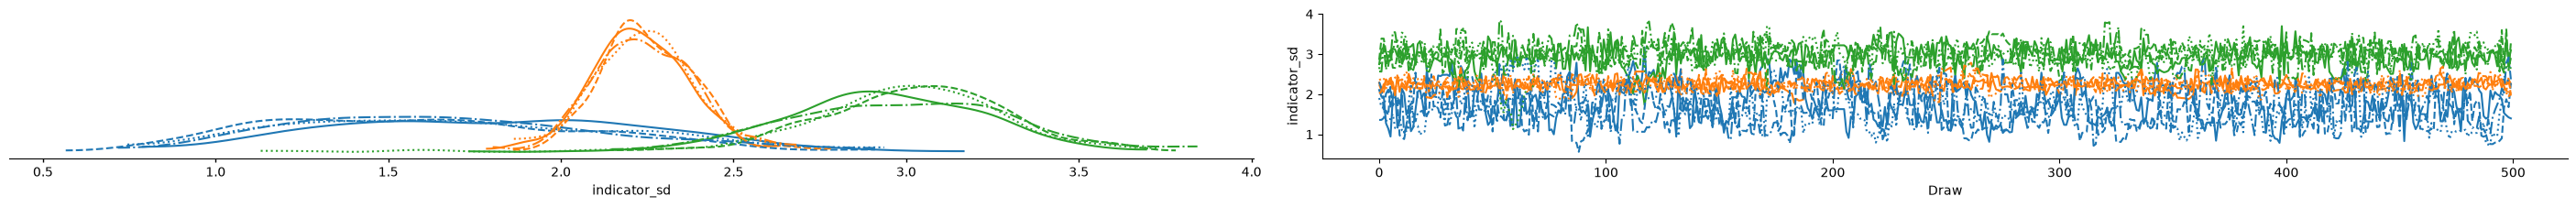

In [25]:
az.plot_trace_dist(recovery_fit, var_names=['indicator_sd'])

## Maps of the recovery

Where the fitted rate of event centers departs from the truth, and which part of the log rate carries the departure. The truth draw keeps its log rate, not its field and offsets separately, so the lower row is the posterior's.

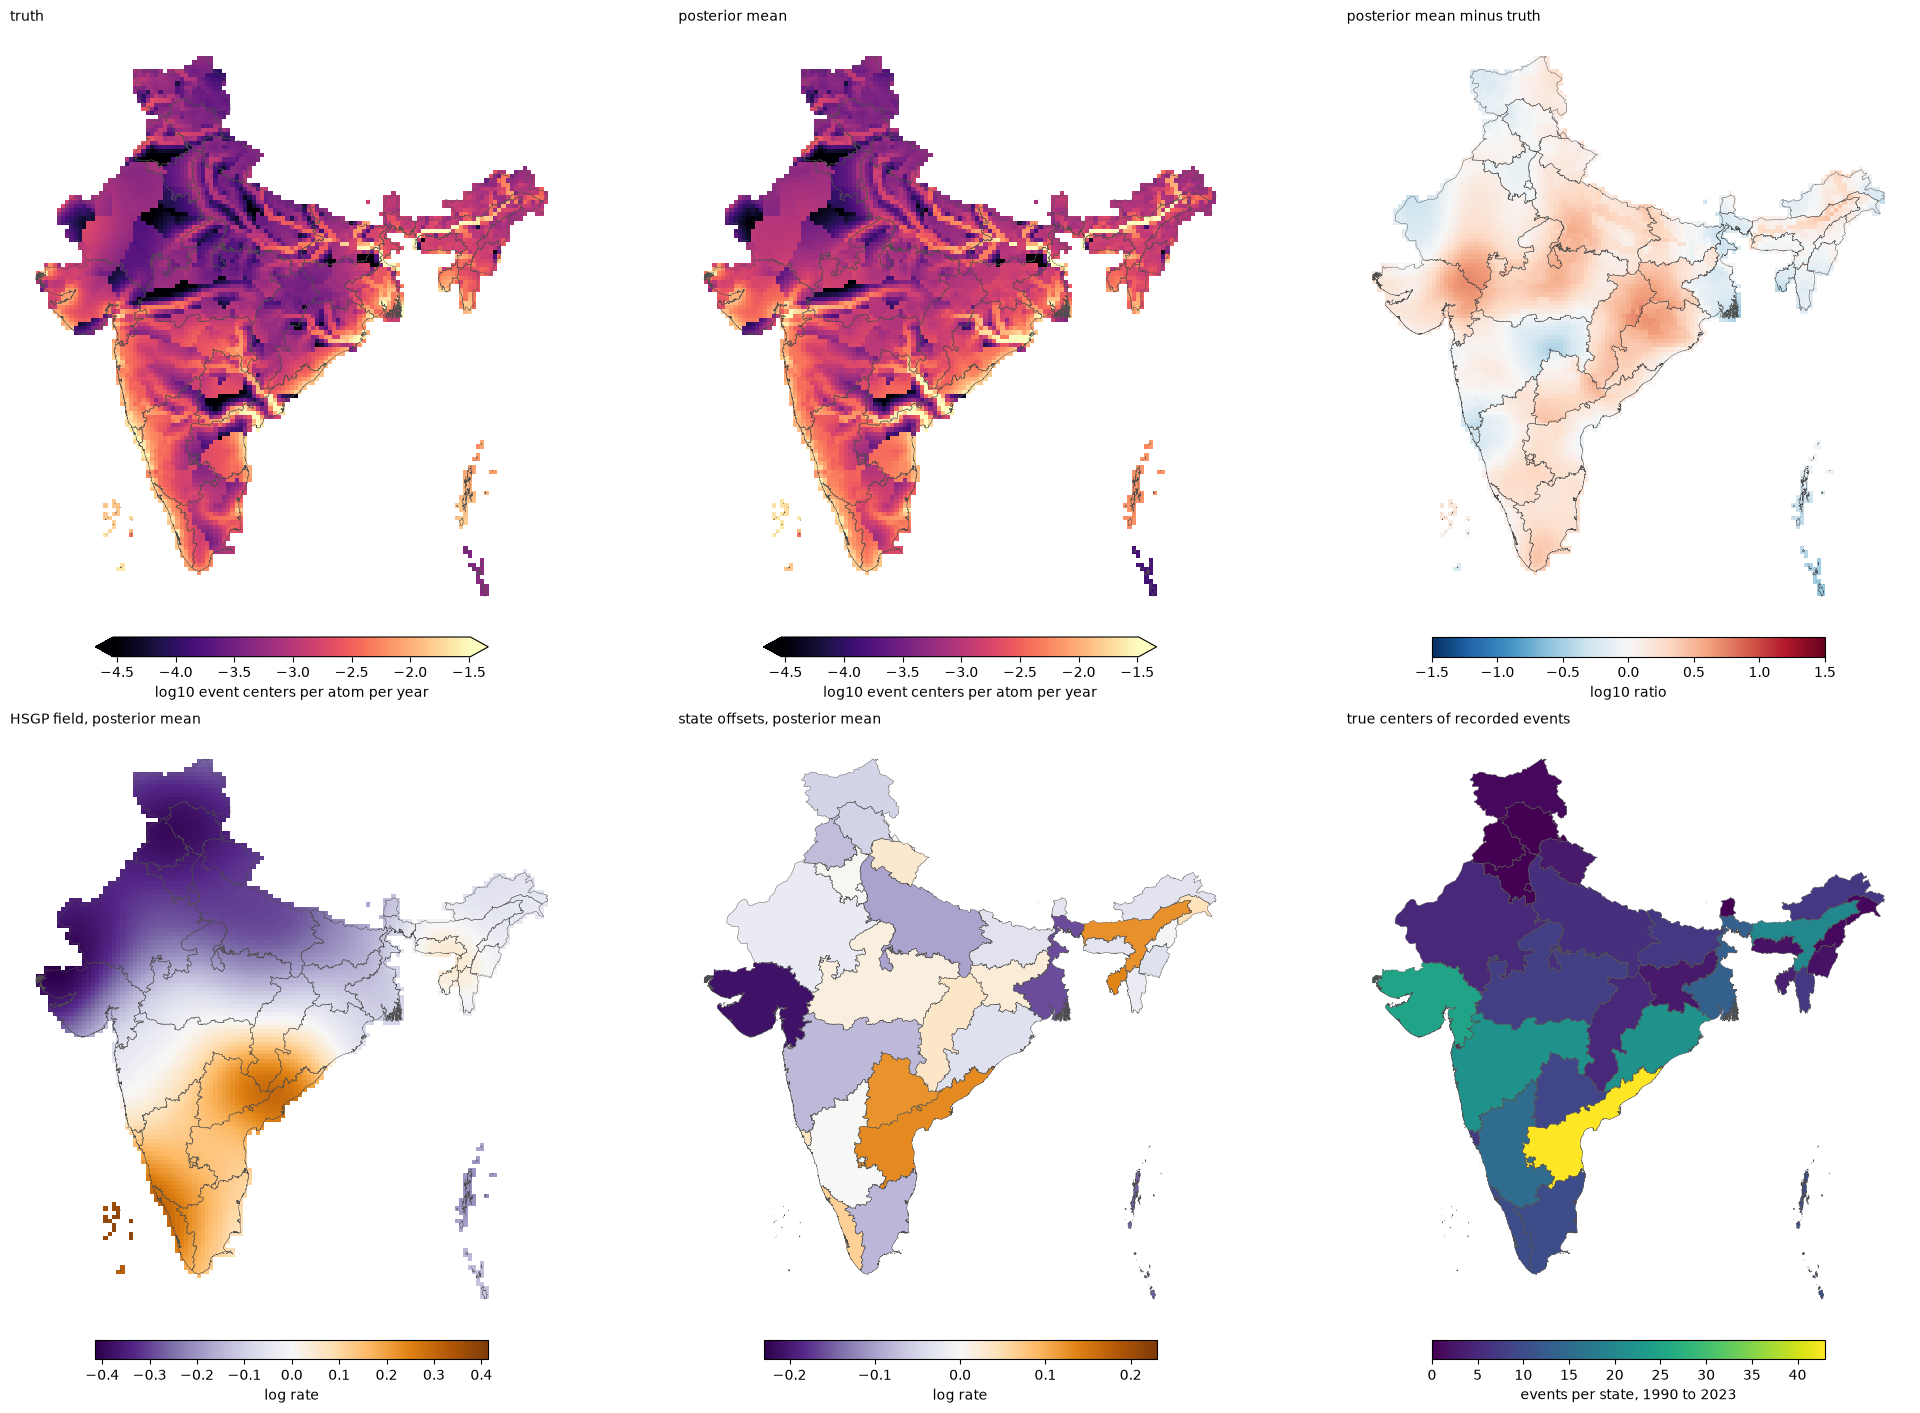

In [26]:
MAP_FIT = recovery_fit
DIFFERENCE_LIMIT = 1.5

atom_cells = gpd.GeoDataFrame(geometry=grid.footprints.reset_index(drop=True), crs=grid.footprints.crs)
state_borders = units["ADM1"].boundary
map_posterior = MAP_FIT.posterior


def symmetric_limits(values):
    """Color limits centered on zero, so a diverging colormap's midpoint marks zero."""
    bound = np.abs(values).max()

    return -bound, bound


true_log10_rate = truth["log_rate"].to_numpy() / np.log(10)
fitted_log10_rate = map_posterior["log_rate"].mean(("chain", "draw")).to_numpy() / np.log(10)
rate_limits = tuple(np.percentile(np.concatenate([true_log10_rate, fitted_log10_rate]), [1, 99]))
field_mean = map_posterior["field"].mean(("chain", "draw")).to_numpy()
state_offset_mean = map_posterior["ADM1_offset"].mean(("chain", "draw")).to_numpy()
# The true centers of the simulated record's events, which the fit sees only through the units each event names.
recorded_centers_per_state = np.bincount(unit_of_atom["ADM1"][simulated["atom"][recorded_index]].astype(int), minlength=n_units["ADM1"])

panels = [
    (atom_cells.assign(value=true_log10_rate), "magma", rate_limits, "truth", "log10 event centers per atom per year"),
    (atom_cells.assign(value=fitted_log10_rate), "magma", rate_limits, "posterior mean", "log10 event centers per atom per year"),
    (atom_cells.assign(value=fitted_log10_rate - true_log10_rate), "RdBu_r", (-DIFFERENCE_LIMIT, DIFFERENCE_LIMIT), "posterior mean minus truth", "log10 ratio"),
    (atom_cells.assign(value=field_mean), "PuOr_r", symmetric_limits(field_mean), "HSGP field, posterior mean", "log rate"),
    (units["ADM1"].assign(value=state_offset_mean), "PuOr_r", symmetric_limits(state_offset_mean), "state offsets, posterior mean", "log rate"),
    (units["ADM1"].assign(value=recorded_centers_per_state), "viridis", None, "true centers of recorded events", f"events per state, {FIRST_YEAR} to {LAST_YEAR}"),
]

figure, axes = plt.subplots(2, 3, figsize=(20, 14))
for axis, (frame, cmap, limits, title, label) in zip(axes.ravel(), panels, strict=True):
    color_limits = {"vmin": limits[0], "vmax": limits[1]} if limits is not None else {}
    frame.plot(column="value",
               ax=axis,
               cmap=cmap,
               legend=True,
               legend_kwds={"label": label, "shrink": 0.6, "location": "bottom", "pad": 0.02},
               **color_limits)
    state_borders.plot(ax=axis,
                       color="0.3",
                       linewidth=0.3)
    axis.set_axis_off()
    axis.set_title(title, loc="left", fontsize=10)
plt.show()

## Damage curves of the recovery

Return levels of the damage of a year's largest event, recorded or not, for India and for each state, from the recovery's posterior against the truth that simulated its record. The hazard enters log damage linearly, so an event's log damage at an exposure bin is normal with the hazard's spread added to the noise, and the rate of events past a damage level is the rate of centers times that tail, summed over atoms and averaged over the record's years. Events arrive as a Poisson process, so a year's largest damage exceeds $d$ with probability $1 - e^{-\lambda(d)}$, and the $T$-year return level solves $\lambda(d) = -\log(1 - 1/T)$.

In [33]:
RETURN_PERIODS = np.array([2, 5, 10, 25, 50, 100, 200])
CURVE_DRAWS = 200
# On log(1 + damage in thousands of US$): from about $400,000 to $26 trillion.
DAMAGE_GRID = np.linspace(6.0, 24.0, 361)
CURVE_PARAMETERS = ["log_rate", "year_effect", "indicator_intercept", "loading", "exposure_elasticity", "income_coefficient", "indicator_sd",
                    "class_probability"]

n_states = n_units["ADM1"]
# Each atom's (state, exposure bin) cell at each epoch, so rates are totalled over the bins the model reads exposure from.
state_bin_of_atom = unit_of_atom["ADM1"][None, :] * n_exposure_bins + exposure_bin(centered_exposure)


def exceedance_rates(parameters):
    """Each state's events per year, recorded or not, whose log damage exceeds each level of DAMAGE_GRID, averaged over the record's years."""
    rate = np.exp(parameters["log_rate"])
    rate_by_cell = np.stack([np.bincount(cells, weights=rate, minlength=n_states * n_exposure_bins) for cells in state_bin_of_atom])
    yearly_rate = rate_by_cell.reshape(n_epochs, n_states, n_exposure_bins)[year_epoch] * np.exp(parameters["year_effect"])[:, None, None]

    spread = np.hypot(parameters["loading"][DAMAGE], parameters["indicator_sd"][DAMAGE])
    # Over (class, year, bin).
    mean = (parameters["indicator_intercept"][DAMAGE][:, None, None]
            + parameters["exposure_elasticity"][DAMAGE] * exposure_bin_centers[None, None, :]
            + parameters["income_coefficient"][DAMAGE] * year_income[None, :, None])
    exceed = ndtr((mean[..., None] - DAMAGE_GRID) / spread)
    class_exceed = np.einsum("c,cybg->ybg", parameters["class_probability"], exceed)

    return np.einsum("ysb,ybg->sg", yearly_rate, class_exceed) / YEARS


def return_levels(rates):
    """The log damage a year's largest event exceeds with probability 1 / T for each T in RETURN_PERIODS, NaN where no year reaches the grid's floor that often."""
    target = -np.log1p(-1.0 / RETURN_PERIODS)
    levels = np.interp(target, rates[::-1], DAMAGE_GRID[::-1])

    return np.where(target > rates[0], np.nan, levels)


def curve_levels(parameters):
    """Return levels for India and for each state, over RETURN_PERIODS."""
    state_rates = exceedance_rates(parameters)

    return return_levels(state_rates.sum(axis=0)), np.stack([return_levels(rates) for rates in state_rates])


curve_posterior = recovery_fit.posterior.to_dataset()[CURVE_PARAMETERS].stack(sample=("chain", "draw"))
curve_samples = np.linspace(0, curve_posterior.sizes["sample"] - 1, CURVE_DRAWS).astype(int)
posterior_levels = [curve_levels({name: curve_posterior[name].isel(sample=sample).to_numpy() for name in CURVE_PARAMETERS})
                    for sample in tqdm(curve_samples)]
india_levels = np.stack([india for india, _ in posterior_levels])
state_levels = np.stack([states for _, states in posterior_levels])
true_india_levels, true_state_levels = curve_levels({name: truth[name].to_numpy() for name in CURVE_PARAMETERS})


def billions(log_damage):
    """US$ billions from log(1 + damage in thousands of US$)."""
    return np.expm1(log_damage) / 1e6


pd.DataFrame({"truth": billions(true_india_levels),
              "posterior median": billions(np.median(india_levels, axis=0)),
              "5th percentile": billions(np.percentile(india_levels, 5, axis=0)),
              "95th percentile": billions(np.percentile(india_levels, 95, axis=0))},
             index=pd.Index(RETURN_PERIODS, name="return period, years")).round(2)

  0%|          | 0/200 [00:00<?, ?it/s]

,truth,posterior median,5th percentile,95th percentile
"return period, years",,,,
2,34.57,27.51,13.35,64.38
5,726.32,358.19,150.18,1438.68
10,7382.04,2470.46,632.54,16709.08
25,26489.12,26489.12,3920.41,26489.12
50,26489.12,26489.12,13291.52,26489.12
100,26489.12,26489.12,26489.12,26489.12
200,26489.12,26489.12,26489.12,26489.12
